# File 8: Rent Forecast (Auckland)

## Purpose
A one- and two-year rent outlook for every Auckland rent area, tested honestly first: models are trained on data up to
September 2024, their forecasts for Oct 2024 – Sep 2026 are scored against what actually happened, and only then is the
winning model run forward to September 2028. Rent only: suburb sale prices are not in the data (File 5).

## Inputs
| File | What |
|---|---|
| `data/clean/rent_timeseries_by_sa2.csv` | Quarterly median rent and new bonds lodged by MBIE rent area (`rent_source_sa2`), 1993 – Jul–Sep 2026 |
| `data/clean/auckland_rent_monthly.csv` | MBIE official Auckland monthly median (File 5) |
| `data/clean/master_flagged.csv`, `risk_value_screen.csv` | SA2 names, flags, new-development marker |

## What is forecast
- **Rent level now** = mean of the quarterly medians published in the last 4 quarters, the same definition as `median_rent_weekly`.
  Scoring a forecast needs 2 or more published quarters in the year being checked.
- **Year 1** = mean rent of the next 4 quarters, **year 2** = the 4 after. Annual means, because single quarters in small areas swing
  by $100+ on a handful of bonds.
- Forecasts are made **once per rent area** (MBIE 2018 SA2s) and copied to the 2023 SA2s that share it.

## Models (deliberately simple)
| Model | Forecast |
|---|---|
| `naive` | Rent stays at today's level |
| `area_trend` | The area's own 10-year growth rate continues |
| `auckland` | A damped-trend model (exponential smoothing on log rent) of the official Auckland series; its growth is applied to every area |
| `blend` | The average of `area_trend` and `auckland` (added after the first run, as a standard forecast combination) |

## Steps
1. Load the series
2. Forecast functions
3. Backtest: train to Sep 2024, score Oct 2024 – Sep 2026
4. Stability check: 13 forecast origins, 2012–2024
5. Prediction bands from past errors, and a check that they hold
6. Forecast to Sep 2028
7. Save outputs

## Outputs
- `data/clean/rent_forecast_by_sa2.csv`: one row per SA2 with a forecast
- `data/clean/rent_forecast_backtest.csv`: error summary by model, horizon and test
- `visualizations/08_*.png`

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
pd.set_option('display.width', 160, 'display.max_columns', 40)
MODELS = ['naive', 'area_trend', 'auckland', 'blend']

### Step 1: Load the series

In [2]:
# STEP 1: LOAD. One column per MBIE rent area; the official Auckland median as quarterly means of the monthly medians.
ts = pd.read_csv(CLEAN / 'rent_timeseries_by_sa2.csv', parse_dates=['quarter'])
area = ts.drop_duplicates(['rent_source_sa2', 'quarter'])
rent = area.pivot(index='quarter', columns='rent_source_sa2', values='median_rent').asfreq('QS-JAN')
lodged = area.pivot(index='quarter', columns='rent_source_sa2', values='lodged_bonds').reindex(rent.index)
akl_m = pd.read_csv(CLEAN / 'auckland_rent_monthly.csv', parse_dates=['month']).set_index('month').median_rent
akl = akl_m.resample('QS-JAN').mean().loc['1993-04-01':]   # first full quarter (series starts Feb 1993)
LAST = rent.index.max()
assert akl.index.max() == LAST and akl_m.index.max() == LAST + pd.DateOffset(months=2)   # last quarter complete
print(f'{rent.shape[1]} rent areas, {rent.index.min():%b %Y} – {LAST:%b %Y} quarters | Auckland series {akl.index.min():%b %Y} – {LAST:%b %Y}')
print(f'Published medians in the latest quarter: {rent.loc[LAST].notna().sum()} areas')

543 rent areas, Jan 1993 – Jul 2026 quarters | Auckland series Apr 1993 – Jul 2026
Published medians in the latest quarter: 507 areas


### Step 2: Forecast functions

In [3]:
# STEP 2: FORECASTS. 'origin' = the last quarter of training data. Every model returns rent for year 1 and year 2.
def window_mean(df, start, end, min_q=2):
    w = df.loc[start:end]
    return w.mean().where(w.notna().sum() >= min_q)      # outcomes need 2+ published quarters of 4

def level(origin):                                       # rent now: the 4 quarters ending at origin (1+ published, as build_master.py)
    return window_mean(rent, origin - pd.DateOffset(months=9), origin, min_q=1)

def actual(origin, h):                                   # what happened in forecast year h (1 or 2)
    return window_mean(rent, origin + pd.DateOffset(months=12 * h - 9), origin + pd.DateOffset(months=12 * h))

def auckland_growth(origin):
    """Damped-trend model of log Auckland rent, fitted on data to origin. Returns year-1 and year-2 growth factors."""
    y = np.log(akl.loc[:origin])
    f = np.exp(ExponentialSmoothing(y, trend='add', damped_trend=True).fit().forecast(8))
    base = np.exp(y.iloc[-4:]).mean()
    return f.iloc[:4].mean() / base, f.iloc[4:].mean() / base, f

def forecast(origin):
    L = level(origin)
    g = (L / window_mean(rent, origin - pd.DateOffset(months=129), origin - pd.DateOffset(months=120))) ** (1 / 10)
    a1, a2, _ = auckland_growth(origin)
    return pd.DataFrame({'level': L, 'naive_1': L, 'naive_2': L, 'area_trend_1': L * g, 'area_trend_2': L * g ** 2,
                         'auckland_1': L * a1, 'auckland_2': L * a2, 'blend_1': L * (g + a1) / 2, 'blend_2': L * (g ** 2 + a2) / 2})

def errors(origin):
    """Percent error of each model against the actual year mean, on areas where every model and the actual exist."""
    f = forecast(origin)
    lod = lodged.loc[origin - pd.DateOffset(months=9):origin].sum()
    out = []
    for h in (1, 2):
        d = f[[f'{m}_{h}' for m in MODELS]].assign(actual=actual(origin, h)).dropna()
        for m in MODELS:
            out.append(pd.DataFrame({'origin': origin, 'h': h, 'model': m, 'rent_area': d.index,
                                     'err_pct': (d[f'{m}_{h}'] / d.actual - 1) * 100, 'lodged_4q': lod.reindex(d.index).values}))
    return pd.concat(out, ignore_index=True)

def summary(e):
    return (e.assign(ae=e.err_pct.abs()).groupby(['h', 'model'])
             .agg(areas=('rent_area', 'nunique'), mape=('ae', 'mean'), median_ape=('ae', 'median'), bias=('err_pct', 'mean'),
                  within_5pct=('ae', lambda x: 100 * (x <= 5).mean())).round(1))

# Sanity check: 'rent now' reproduces median_rent_weekly from build_master.py
m = pd.read_csv(CLEAN / 'master_flagged.csv')
chk = m.dropna(subset=['median_rent_weekly'])
assert np.allclose(chk.rent_source_sa2.map(level(LAST)), chk.median_rent_weekly, atol=0.01)
print('Level definition matches median_rent_weekly')

Level definition matches median_rent_weekly


### Step 3: Backtest — train to Sep 2024, score Oct 2024 – Sep 2026

In [4]:
# STEP 3: THE BACKTEST. Nothing after the Jul-Sep 2024 quarter is used to make these forecasts.
ORIGIN = pd.Timestamp('2024-07-01')
bt = errors(ORIGIN)
bt_sum = summary(bt)
a1, a2, _ = auckland_growth(ORIGIN)
act_akl = [akl.loc[ORIGIN + pd.DateOffset(months=12 * h - 9):ORIGIN + pd.DateOffset(months=12 * h)].mean() /
           akl.loc[ORIGIN - pd.DateOffset(months=9):ORIGIN].mean() for h in (1, 2)]
print(f'Auckland model, trained to Sep 2024, expected {100 * (a1 - 1):+.1f}% (year 1) and {100 * (a2 - 1):+.1f}% (year 2); '
      f'the official series actually moved {100 * (act_akl[0] - 1):+.1f}% and {100 * (act_akl[1] - 1):+.1f}%')
print('Year 1 = Oct 2024 – Sep 2025, year 2 = Oct 2025 – Sep 2026. Error = forecast / actual - 1 (positive = forecast too high)')
bt_sum

Auckland model, trained to Sep 2024, expected +0.9% (year 1) and +2.0% (year 2); the official series actually moved -0.1% and -0.9%
Year 1 = Oct 2024 – Sep 2025, year 2 = Oct 2025 – Sep 2026. Error = forecast / actual - 1 (positive = forecast too high)


areas  mape  median_ape  bias  within_5pct
h model                                                 
1 area_trend    507   7.3         6.4   5.4         41.8
  auckland      507   5.0         3.6   1.9         63.9
  blend         507   6.0         4.8   3.6         51.9
  naive         507   4.7         3.4   1.0         65.7
2 area_trend    506  11.4        10.5   9.8         20.0
  auckland      506   6.2         5.1   2.8         49.4
  blend         506   8.5         7.5   6.3         31.6
  naive         506   5.5         3.9   0.8         60.1

In [5]:
# Error by sample size (new bonds over the 4 training quarters): small areas miss by more, whatever the model
band = lambda n: pd.cut(n, [-1, 29, 99, np.inf], labels=['under 30', '30-99', '100+'])
(bt.assign(sample=band(bt.lodged_4q), ae=bt.err_pct.abs())
   .pivot_table(index=['h', 'sample'], columns='model', values='ae', aggfunc='mean', observed=True).round(1))

model       area_trend  auckland  blend  naive
h sample                                      
1 under 30        11.7       9.3   10.3    9.1
  30-99            7.2       4.9    5.9    4.6
  100+             6.1       3.9    4.8    3.7
2 under 30        16.7      11.4   13.7   10.7
  30-99           11.1       5.8    8.2    5.1
  100+            10.2       5.3    7.5    4.5

### Step 4: Stability check — 13 forecast origins

In [6]:
# STEP 4: ONE TEST PERIOD IS ONE DRAW. 2024-26 was a cooling period, which flatters a flat forecast. Repeat the test from
# every September 2012-2024 (13 origins; the latest that can be scored two years out is Sep 2024) and choose on all of them.
origins = pd.date_range('2012-07-01', '2024-07-01', freq='12MS')
roll = pd.concat([errors(o) for o in origins], ignore_index=True)
roll_sum = summary(roll)
by_origin = roll.assign(ae=roll.err_pct.abs()).pivot_table(index='origin', columns=['h', 'model'], values='ae', aggfunc='mean')
by_origin.index = by_origin.index.year
wins = pd.DataFrame({h: by_origin[h].idxmin(axis=1).value_counts() for h in (1, 2)}).fillna(0).astype(int)
wins.columns = ['year 1', 'year 2']
POOLED_BEST = roll_sum.groupby('model').mape.mean().idxmin()
# DECISION (to review): use 'auckland'. Over 13 origins it is within about half a point of the best ('blend'), and in the
# designated 2024-26 test it beats 'blend' and 'area_trend' clearly; both of those carry the area's 10-year growth into a
# market that has turned. 'naive' wins 2024-26 only and is worst over the 13 origins.
BEST = 'auckland'
print(f'Lowest average error over 13 origins: {POOLED_BEST} | model used: {BEST}')
print('Origins won (lowest mean absolute error) by each model:'); print(wins)
by_origin.round(1)

Lowest average error over 13 origins: blend | model used: auckland
Origins won (lowest mean absolute error) by each model:
            year 1  year 2
blend            5       5
auckland         4       4
area_trend       3       2
naive            1       2


h               1                               2                     
model  area_trend auckland blend naive area_trend auckland blend naive
origin                                                                
2012          4.6      4.5   4.5   5.5        5.3      5.7   5.2   8.6
2013          4.4      4.2   4.3   5.5        6.3      6.0   6.1  10.7
2014          5.3      4.7   5.0   7.2        6.6      6.0   6.3  11.4
2015          4.7      5.0   4.6   6.1        5.6      6.5   5.5   9.8
2016          4.8      4.6   4.7   5.8        5.8      5.2   5.3   8.1
2017          5.1      4.9   4.8   5.5        6.3      6.2   5.4   7.5
2018          4.8      4.5   4.5   5.1        5.7      5.8   5.1   7.0
2019          5.0      4.7   4.7   5.3        6.6      7.2   6.2   8.6
2020          5.6      6.4   5.7   6.6        6.3      8.6   6.6   8.9
2021          5.2      5.1   5.1   5.7        6.2      5.4   5.7   8.7
2022          5.3      6.9   5.5   6.1        6.5     11.7   8.0   9.9
2023          5.2      5.8   5.3   6.4        6.8      9.6   8.0   5.6
2024          7.3      5.0   6.0   4.7       11.4      6.2   8.5   5.5

In [7]:
roll_sum

areas  mape  median_ape  bias  within_5pct
h model                                                 
1 area_trend    529   5.2         3.6   0.6         63.3
  auckland      529   5.1         3.7  -0.5         62.9
  blend         529   5.0         3.4   0.0         65.1
  naive         529   5.8         4.7  -3.4         53.2
2 area_trend    526   6.6         4.6   1.3         52.9
  auckland      526   6.9         5.6  -1.8         45.5
  blend         526   6.3         4.7  -0.3         52.5
  naive         526   8.5         7.8  -6.7         29.9

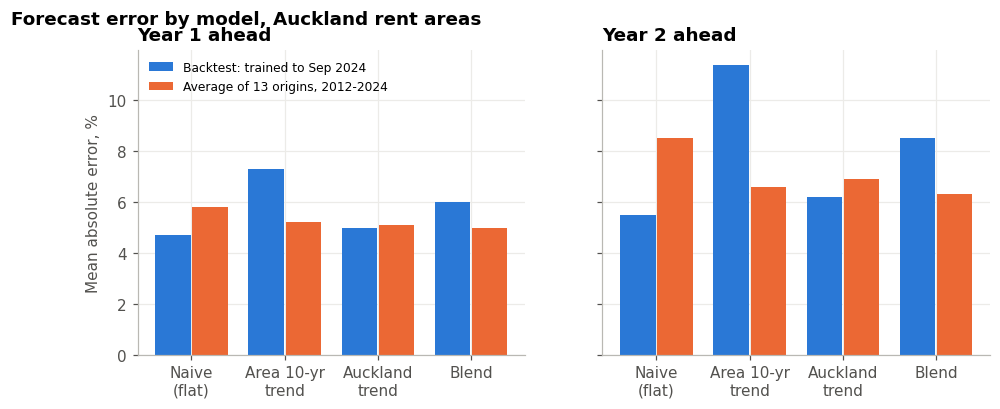

In [8]:
# Chart: mean absolute error by model, the 2024 backtest against the 13-origin average
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, h in zip(axes, (1, 2)):
    x = np.arange(len(MODELS))
    ax.bar(x - 0.2, bt_sum.loc[h].loc[MODELS, 'mape'], 0.38, color=BLUE, label='Backtest: trained to Sep 2024')
    ax.bar(x + 0.2, roll_sum.loc[h].loc[MODELS, 'mape'], 0.38, color=ORANGE, label='Average of 13 origins, 2012-2024')
    ax.set_xticks(x, ['Naive\n(flat)', 'Area 10-yr\ntrend', 'Auckland\ntrend', 'Blend']); ax.set_title(f'Year {h} ahead')
axes[0].set_ylabel('Mean absolute error, %'); axes[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.suptitle('Forecast error by model, Auckland rent areas', x=0.01, ha='left', fontweight='bold')
fig.savefig(VIZ / '08_backtest_error.png'); plt.show()

### Step 5: Prediction bands from past errors

In [9]:
# STEP 5: 80% BANDS. Taken from the chosen model's own errors (10th and 90th percentile), separately for thin samples, since
# small areas miss by more. Honesty check: bands built only from origins before 2024 must cover about 80% of 2024-26 outcomes.
def bands(e):
    e = e[e.model == BEST].assign(thin=e.lodged_4q < 30)
    return e.groupby(['h', 'thin']).err_pct.quantile([0.1, 0.9]).unstack()

def cover(e, q):
    e = e[e.model == BEST].assign(thin=e.lodged_4q < 30)
    key = pd.MultiIndex.from_arrays([e.h, e.thin])
    lo, hi = q[0.1].reindex(key).values, q[0.9].reindex(key).values
    return 100 * ((e.err_pct.values >= lo) & (e.err_pct.values <= hi)).mean()

q_past = bands(roll[roll.origin < ORIGIN])
COVER = cover(bt, q_past)
print(f'Bands from 2012-2023 origins cover {COVER:.0f}% of the 2024-26 outcomes (target 80%)')
Q = bands(roll)     # final bands use all 13 origins
Q.round(1)

Bands from 2012-2023 origins cover 79% of the 2024-26 outcomes (target 80%)


0.1   0.9
h thin             
1 False  -7.8   6.6
  True  -13.8  15.4
2 False -11.3   8.1
  True  -17.2  17.7

### Step 6: Forecast to September 2028

In [10]:
# STEP 6: RUN THE CHOSEN MODEL FROM THE LATEST QUARTER. Error = forecast/actual - 1, so the actual lies in
# forecast/(1 + q90) .. forecast/(1 + q10).
f = forecast(LAST)
lod_now = lodged.loc[LAST - pd.DateOffset(months=9):LAST].sum()
fc = pd.DataFrame({'rent_now': f.level, 'lodged_4q': lod_now}).dropna(subset=['rent_now'])
fc['flag_thin_sample'] = fc.lodged_4q < 30
for h in (1, 2):
    fc[f'forecast_rent_y{h}'] = f[f'{BEST}_{h}']
    lo, hi = fc.flag_thin_sample.map(Q.loc[h][0.9]), fc.flag_thin_sample.map(Q.loc[h][0.1])
    fc[f'y{h}_low'], fc[f'y{h}_high'] = fc[f'forecast_rent_y{h}'] / (1 + lo / 100), fc[f'forecast_rent_y{h}'] / (1 + hi / 100)
    fc[f'change_y{h}_pct'] = (fc[f'forecast_rent_y{h}'] / fc.rent_now - 1) * 100
g1, g2, akl_f = auckland_growth(LAST)
P1 = f'{LAST + pd.DateOffset(months=3):%b %Y} - {LAST + pd.DateOffset(months=14):%b %Y}'
P2 = f'{LAST + pd.DateOffset(months=15):%b %Y} - {LAST + pd.DateOffset(months=26):%b %Y}'
print(f'Model: {BEST} | year 1 = {P1}, year 2 = {P2}')
print(f'Auckland official median: ${akl.loc[LAST - pd.DateOffset(months=9):LAST].mean():.0f} over the last 4 quarters; '
      f'damped trend expects {100 * (g1 - 1):+.1f}% in year 1 and {100 * (g2 - 1):+.1f}% in year 2')
print(f'{len(fc)} rent areas forecast; {fc.flag_thin_sample.sum()} on thin samples (under 30 new bonds in 4 quarters)')
fc[['rent_now', 'forecast_rent_y1', 'y1_low', 'y1_high', 'forecast_rent_y2', 'y2_low', 'y2_high']].describe().round(0).T[['50%', 'min', 'max']]

Model: auckland | year 1 = Oct 2026 - Sep 2027, year 2 = Oct 2027 - Sep 2028
Auckland official median: $645 over the last 4 quarters; damped trend expects -0.3% in year 1 and -0.6% in year 2
527 rent areas forecast; 36 on thin samples (under 30 new bonds in 4 quarters)


,50%,min,max
rent_now,671.0,300.0,1036.0
forecast_rent_y1,669.0,299.0,1032.0
y1_low,625.0,281.0,969.0
y1_high,728.0,324.0,1120.0
forecast_rent_y2,667.0,298.0,1030.0
y2_low,615.0,276.0,953.0
y2_high,755.0,336.0,1161.0


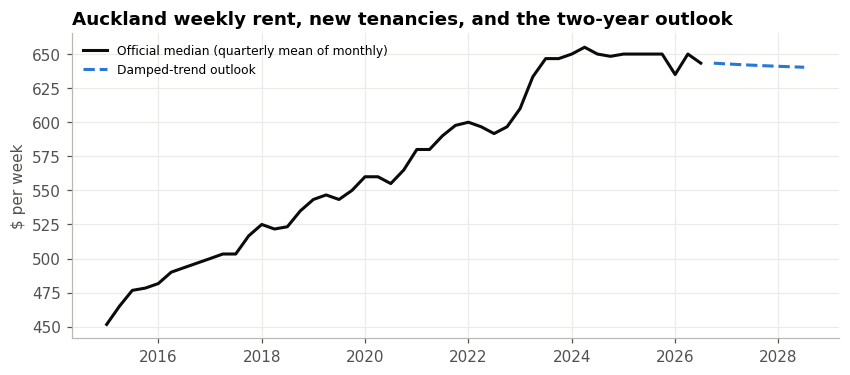

In [11]:
# Chart: the official Auckland series with the damped-trend outlook
h = akl.loc['2015-01-01':]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(h.index, h, color=INK, lw=2, label='Official median (quarterly mean of monthly)')
ax.plot(akl_f.index, akl_f, color=BLUE, lw=2, ls='--', label='Damped-trend outlook')
ax.set_title('Auckland weekly rent, new tenancies, and the two-year outlook'); ax.set_ylabel('$ per week')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.savefig(VIZ / '08_auckland_outlook.png'); plt.show()

### Step 7: Save outputs

In [12]:
# STEP 7: SAVE. One row per 2023 SA2 that has a rent figure; areas sharing a rent series share its forecast.
risk = pd.read_csv(CLEAN / 'risk_value_screen.csv', usecols=['sa2_code', 'is_new_development'])
out = (m[['sa2_code', 'sa2_name', 'rent_source_sa2', 'flag_borrowed_rent', 'analysis_ready']]
       .merge(fc, left_on='rent_source_sa2', right_index=True, how='inner')
       .merge(risk, on='sa2_code', how='left'))
out['is_new_development'] = out.is_new_development.eq(True)
out['model'], out['year1_period'], out['year2_period'] = BEST, P1, P2
cols = ['sa2_code', 'sa2_name', 'rent_source_sa2', 'rent_now', 'forecast_rent_y1', 'y1_low', 'y1_high', 'change_y1_pct',
        'forecast_rent_y2', 'y2_low', 'y2_high', 'change_y2_pct', 'lodged_4q', 'flag_thin_sample', 'flag_borrowed_rent',
        'is_new_development', 'analysis_ready', 'model', 'year1_period', 'year2_period']
path = CLEAN / 'rent_forecast_by_sa2.csv'
out[cols].round(1).to_csv(path, index=False)
bt_out = pd.concat([bt_sum.assign(test='trained to Sep 2024'), roll_sum.assign(test='13 origins 2012-2024')]).reset_index()
bt_out.to_csv(CLEAN / 'rent_forecast_backtest.csv', index=False)
check = pd.read_csv(path)
assert check.sa2_code.is_unique and (check.y1_low <= check.forecast_rent_y1).all() and (check.forecast_rent_y1 <= check.y1_high).all()
assert np.allclose(check.rent_now, m.set_index('sa2_code').loc[check.sa2_code, 'median_rent_weekly'], atol=0.06)
print(f'Saved {path} ({len(check)} SA2s on {check.rent_source_sa2.nunique()} rent areas) and rent_forecast_backtest.csv')

Saved data\clean\rent_forecast_by_sa2.csv (600 SA2s on 527 rent areas) and rent_forecast_backtest.csv


# File 8: Rent Forecast - Summary

## What we did
Tested four simple models on Auckland's MBIE rent areas: trained on data up to September 2024, scored on what happened from
October 2024 to September 2026, then repeated from every September 2012–2024 (13 tests) so one cooling period can't decide the
choice. The chosen model then forecasts the year to September 2027 and the year to September 2028, with 80% bands from its past errors.

## Key findings
| Question | Answer |
|---|---|
| How accurate is a one-year rent forecast for an area? | **About 5% average error.** Trained to Sep 2024, the Auckland-trend model missed the year to Sep 2025 by 5.0% on average (median 3.6%; 64% of areas within 5%) and the year to Sep 2026 by 6.2% |
| Does an area's own history help? | **No.** Carrying an area's 10-year growth forward was worst in the 2024–26 test (7.3% and 11.4% error), because it kept projecting growth into a market that turned. Over 13 tests it ties with the Auckland trend |
| Was the model right about the turn? | **Partly.** Trained to Sep 2024 it expected Auckland rent +0.9% then +2.0%; the official series moved −0.1% and −0.9%. A flat forecast happened to do best in this one test (4.7%, 5.5%) and is worst over 13 tests (5.8%, 8.5%) |
| Small areas | Error roughly doubles where an area had under 30 new bonds in a year (9.3% against 3.9% for 100+, year 1) |
| The forecast | Auckland rent **−0.3%** in the year to Sep 2027 and **−0.6%** in the year to Sep 2028 against the last four quarters ($645 official median). Every area gets the same percentage; areas differ by their current level and the width of their band |
| How wide is the band? | 80% band in a typical area about **−$40 / +$55 a week** for year 1 and **−$50 / +$85** for year 2; about twice as wide on thin samples (36 rent areas) |
| Do the bands hold? | Bands built only from 2012–2023 tests covered **79%** of 2024–26 outcomes (target 80%) |

## Decision to review
| Decision | Why | Alternative |
|---|---|---|
| Use the Auckland trend model, not the lowest 13-test error (`blend`, 5.0% / 6.3% against 5.1% / 6.9%) | Within about half a point over 13 tests and clearly better in the 2024–26 test you set (5.0% / 6.2% against 6.0% / 8.5%); it is the only one that responds to the current cooling | `blend` would add about 1.5% a year of area-specific growth; `rent_forecast_backtest.csv` keeps every model's scores |
| `blend` was added after the first run | A standard forecast combination, tested on the same 13 origins; reported so the search is visible | — |

## Caveats
- **A forecast of new-tenancy rent** (bond lodgements), not what sitting tenants pay. Annual means, not a single month.
- **No cause:** the model knows nothing about migration, building, interest rates or policy; it extrapolates Auckland's recent trend, damped.
- **Area differences in growth are not forecast**: the backtest shows area trends add noise, not skill.
- Areas sharing a rent series (`flag_borrowed_rent`) share the forecast; new developments (`is_new_development`) forecast from the 2018 parent area.
- 80% bands mean about 1 area in 5 will land outside them.

## What this means for the dashboard and agent
- Show forecast rent with its band and period ("year to Sep 2027"), never as a single certain number.
- Say "about 5% typical error in a one-year test" and that the forecast is the Auckland trend applied to the area's current rent.

## Outputs
- `data/clean/rent_forecast_by_sa2.csv`: 600 SA2s on 527 rent areas: `rent_now`, `forecast_rent_y1`, `y1_low`, `y1_high`, `change_y1_pct`, the same for y2, `lodged_4q`, `flag_thin_sample`, `flag_borrowed_rent`, `is_new_development`, `analysis_ready`, `model`, `year1_period`, `year2_period`
- `data/clean/rent_forecast_backtest.csv`: error by model and horizon for the 2024 test and the 13-origin average
- `visualizations/08_backtest_error.png`, `08_auckland_outlook.png`